# code_127 · Forward beam solves and identifiable stiffness recovery

**Book:** section 25.1. A self-contained scientific-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_25_GUIDE.md), [run evidence](../CHAPTER_25_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_127).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2927;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2927


<a id="beam-task-contract"></a>
 ## Given mechanics, observed sensors, inferred parameters
 A unit-length, simply supported Euler–Bernoulli beam has constant bending stiffness EI and uniform transverse load q, with EI*D4w=q, w(0)=w(1)=0 and w''(0)=w''(1)=0. The analytic polynomial is available as independent generated truth. Solve the first-order four-state boundary-value system with native SciPy at two mesh/tolerance settings. Three interior displacement sensors observe a beam with EI=2 and known q=3, with declared independent Gaussian noise. Recover compliance by linear least squares, then invert only a positive compliance. Also let both q and EI be unknown: the displacement-only likelihood identifies their ratio, not each separately. Exact equal-ratio predictions and sensitivity rank expose that ambiguity. No field beam or unknown boundary condition is inferred.


,initial_nodes,final_nodes,tolerance,max_displacement_error,max_boundary_residual
0,8,15,1.000000e-05,1.016829e-07,4.496004e-22
1,16,181,1.000000e-08,3.721093e-12,1.677254e-26


Known-load stiffness estimate: 2.00276944524686 joint-parameter rank: 1


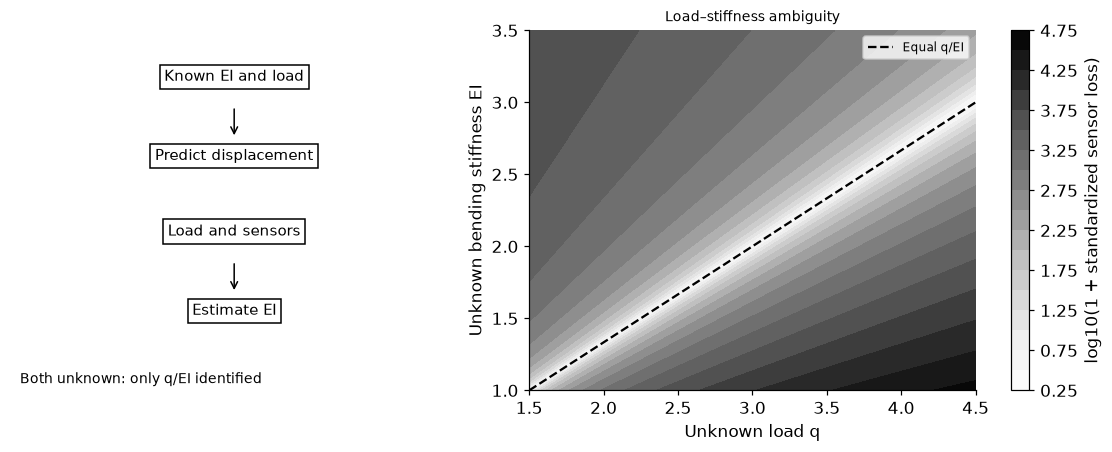

In [2]:
from scipy.integrate import solve_bvp
def shape(x):return (x-2*x**3+x**4)/24
def exact(x,q,stiffness):return q/stiffness*shape(x)
q_true,EI_true=3.,2.;grid=np.linspace(0,1,401);solver_rows=[];solutions=[]
for nodes,tolerance in [(8,1e-5),(16,1e-8)]:
    mesh=np.linspace(0,1,nodes)
    def rhs(x,y):return np.vstack([y[1],y[2],y[3],np.full(len(x),q_true/EI_true)])
    def bc(a,b):return np.array([a[0],b[0],a[2],b[2]])
    sol=solve_bvp(rhs,bc,mesh,np.zeros((4,nodes)),tol=tolerance,max_nodes=1000);assert sol.success
    prediction=sol.sol(grid)[0];solutions.append(prediction);solver_rows.append({'initial_nodes':nodes,'final_nodes':len(sol.x),'tolerance':tolerance,'max_displacement_error':float(np.max(np.abs(prediction-exact(grid,q_true,EI_true)))),'max_boundary_residual':float(np.max(np.abs(bc(sol.y[:,0],sol.y[:,-1]))))})
sensor_x=np.array([.2,.5,.8]);noise_sd=.00015;sensor_y=exact(sensor_x,q_true,EI_true)+rng.normal(0,noise_sd,len(sensor_x));a=q_true*shape(sensor_x);compliance=float(a@sensor_y/(a@a));assert compliance>0;EI_est=1/compliance
q_grid=np.linspace(1.5,4.5,100);EI_grid=np.linspace(1.,3.5,100);loss=np.mean((q_grid[None,:,None]/EI_grid[:,None,None]*shape(sensor_x)[None,None,:]-sensor_y)**2,axis=2)/noise_sd**2
J=np.stack([shape(sensor_x)/EI_true,-q_true*shape(sensor_x)/EI_true**2],axis=1)/noise_sd;singular=np.linalg.svd(J,compute_uv=False);assert singular[1]<1e-12*singular[0]
np.testing.assert_allclose(exact(grid,3,2),exact(grid,4.5,3),atol=1e-16);assert solver_rows[-1]['max_displacement_error']<1e-9
RESULTS.update(solver_refinement=solver_rows,known_load=q_true,true_stiffness=EI_true,recovered_stiffness=EI_est,sensor_positions=sensor_x.tolist(),sensor_noise_sd=noise_sd,sensitivity_singular_values=singular.tolist(),sensitivity_rank=int(np.linalg.matrix_rank(J)),equal_ratio_max_difference=float(np.max(np.abs(exact(grid,3,2)-exact(grid,4.5,3)))))
display(pd.DataFrame(solver_rows));print('Known-load stiffness estimate:',EI_est,'joint-parameter rank:',np.linalg.matrix_rank(J))
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].axis('off')
for y,label in [(.86,'Known EI and load'),(.64,'Predict displacement'),(.43,'Load and sensors'),(.21,'Estimate EI')]:axes[0].text(.5,y,label,ha='center',bbox=dict(boxstyle='square',fc='white'),fontsize=10)
for start,end in [(.79,.70),(.36,.27)]:axes[0].annotate('',xy=(.5,end),xytext=(.5,start),arrowprops=dict(arrowstyle='->'))
axes[0].text(.02,.02,'Both unknown: only q/EI identified',fontsize=9)
im=axes[1].contourf(q_grid,EI_grid,np.log10(1+loss),levels=16,cmap='Greys');axes[1].plot(q_grid,q_grid/(q_true/EI_true),'k--',label='Equal q/EI');axes[1].set(xlabel='Unknown load q',ylabel='Unknown bending stiffness EI',title='Load–stiffness ambiguity');axes[1].legend(fontsize=8);fig.colorbar(im,ax=axes[1],label='log10(1 + standardized sensor loss)');plt.show()


<a id="reference-and-inverse-audit"></a>
 ## A parameter estimate requires the declared observation model
 The known-load fit uses only three noisy sensors; the dense analytic curve and converged numerical solution assess reconstruction rather than supply additional fit targets. The joint sensitivity has two columns but rank one. A prior could select one point on its ridge without adding displacement information. Unknown sensor gain, supports, load shape or spatially varying stiffness would alter the inverse task. Small reference error validates this simple implementation, not the Euler–Bernoulli approximation for every real structure. Change the sensor positions or noise and repeat without interpreting one estimate as a confidence interval.


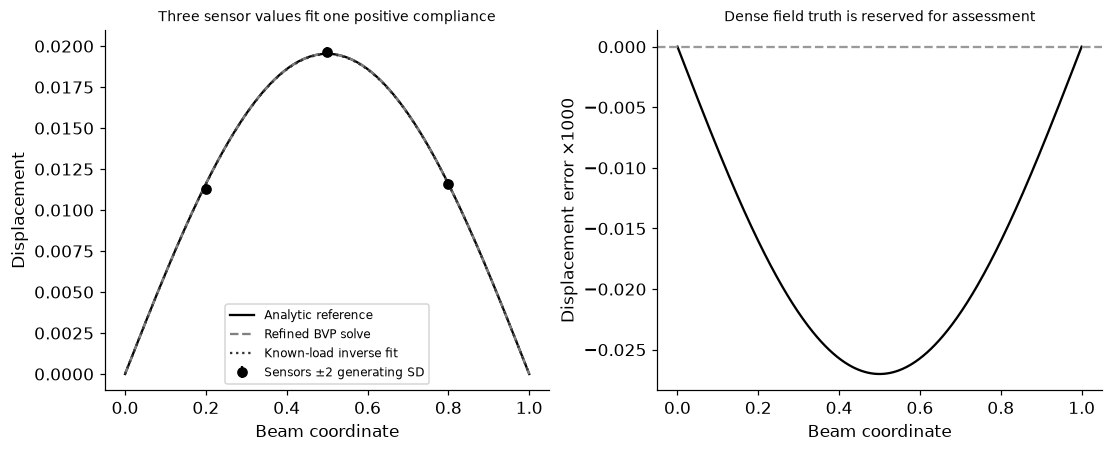

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(grid,exact(grid,q_true,EI_true),'k-',label='Analytic reference');axes[0].plot(grid,solutions[-1],'--',color='.5',label='Refined BVP solve');axes[0].plot(grid,exact(grid,q_true,EI_est),':',color='.2',label='Known-load inverse fit');axes[0].errorbar(sensor_x,sensor_y,yerr=2*noise_sd,fmt='o',color='black',label='Sensors ±2 generating SD');axes[0].set(xlabel='Beam coordinate',ylabel='Displacement',title='Three sensor values fit one positive compliance');axes[0].legend(fontsize=8)
axes[1].plot(grid,(exact(grid,q_true,EI_est)-exact(grid,q_true,EI_true))*1000,color='black');axes[1].axhline(0,color='.6',linestyle='--');axes[1].set(xlabel='Beam coordinate',ylabel='Displacement error ×1000',title='Dense field truth is reserved for assessment');plt.show()
assert np.all(np.isfinite(loss)) and RESULTS['sensitivity_rank']==1


In [4]:
summary={'example_id':'code_127','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native beam boundary-value solver', 'sparse observation operator', 'known-load stiffness recovery', 'joint load-stiffness nonidentifiability', 'reference refinement and sensitivity rank'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native beam boundary-value solver", "sparse observation operator", "known-load stiffness recovery", "joint load-stiffness nonidentifiability", "reference refinement and sensitivity rank"], "elapsed_seconds": 0.946, "example_id": "code_127", "hardware": "Darwin arm64 CPU", "results": {"equal_ratio_max_difference": 0.0, "known_load": 3.0, "recovered_stiffness": 2.00276944524686, "sensitivity_rank": 1, "sensitivity_singular_values": [102.18396896153271, 2.1168814513605073e-15], "sensor_noise_sd": 0.00015, "sensor_positions": [0.2, 0.5, 0.8], "solver_refinement": [{"final_nodes": 15, "initial_nodes": 8, "max_boundary_residual": 4.496003963831032e-22, "max_displacement_error": 1.0168289254694485e-07, "tolerance": 1e-05}, {"final_nodes": 181, "initial_nodes": 16, "max_boundary_residual": 1.6772539622690948e-26, "max_displacement_error": 3.721092878272714e-12, "tolerance": 1e-08}], "true_stiffness": 2.0}, "seed": 2927, "versions": {"matplotli